# 04 - Neurons and Regions (Mustafa, S1.11)

## Plan

1. Load the ready sessions from `data/processed`.
2. Count the neurons and the regions in each session.
3. Count the neurons of every brain region across all sessions.
4. Show which regions each session has.
5. Count how many good units the excluded regions removed in each session.
6. Look at the firing rates of the neurons in the pre-movement window.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the brain-decoding repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.common.settings import load_config, list_processed_sessions, load_session

config = load_config()
excluded = config["data"]["excluded_regions"]
min_per_region = config["experiments"]["min_neurons_per_region"]

ready = list(list_processed_sessions())
if not ready:
    raise SystemExit("No processed sessions found. Run: python -m src.data.build_dataset")

sessions = {sid: load_session(sid) for sid in ready}
print("Sessions loaded:", len(sessions))
print("Feature window (seconds):", config["data"]["window"])
print("Excluded regions:", excluded)
print("Minimum neurons per region:", min_per_region)

Sessions loaded: 10
Feature window (seconds): [-0.1, 0.0]
Excluded regions: ['root', 'void']
Minimum neurons per region: 5


## 1. Neurons in each session

In [2]:
rows = []
for sid, d in sessions.items():
    X = np.asarray(d["X"], dtype=float)
    counts = pd.Series(np.asarray(d["neuron_region"]).astype(str)).value_counts()
    rows.append({
        "session_id": sid,
        "n_trials": X.shape[0],
        "n_neurons": X.shape[1],
        "n_regions": int(counts.size),
        "n_regions_with_min": int((counts >= min_per_region).sum()),
        "largest_region": counts.index[0],
        "largest_region_neurons": int(counts.iloc[0]),
    })

per_session = pd.DataFrame(rows).sort_values("n_neurons", ascending=False).reset_index(drop=True)
display(per_session)
print("Neurons in all sessions:", int(per_session["n_neurons"].sum()))
print("Trials in all sessions:", int(per_session["n_trials"].sum()))

,session_id,n_trials,n_neurons,n_regions,n_regions_with_min,largest_region,largest_region_neurons
0,746d1902-fa59-4cab-b0aa-013be36060d5,481,429,17,12,PO,111
1,ee40aece-cffd-4edb-a4b6-155f158c666a,527,427,15,13,MD,107
2,f10efe41-0dc0-44d0-8f26-5ff68dca23e9,429,396,9,8,CUL4 5,219
3,56b57c38-2699-4091-90a8-aba35103155e,415,391,13,9,CENT2,77
4,4d8c7767-981c-4347-8e5e-5d5fffe38534,562,389,10,8,MOs,135
5,6274dda8-3a59-4aa1-95f8-a8a549c46a26,591,349,10,9,PAG,84
6,2bdf206a-820f-402f-920a-9e86cd5388a4,427,346,9,9,APN,63
7,8207abc6-6b23-4762-92b4-82e05bed5143,491,332,8,6,CP,104
8,dfbe628d-365b-461c-a07f-8b9911ba83aa,516,331,7,7,ORBvl,139
9,09394481-8dd2-4d5c-9327-f2753ede92d7,433,326,12,11,V,61


Neurons in all sessions: 3716
Trials in all sessions: 4872


## 2. Neurons per brain region across all sessions

Distinct regions in the whole dataset: 65


,neurons
ORBvl,284
CUL4 5,272
MOs,234
LP,217
PO,199
AON,144
Eth,138
GRN,128
VISa,124
IRN,116


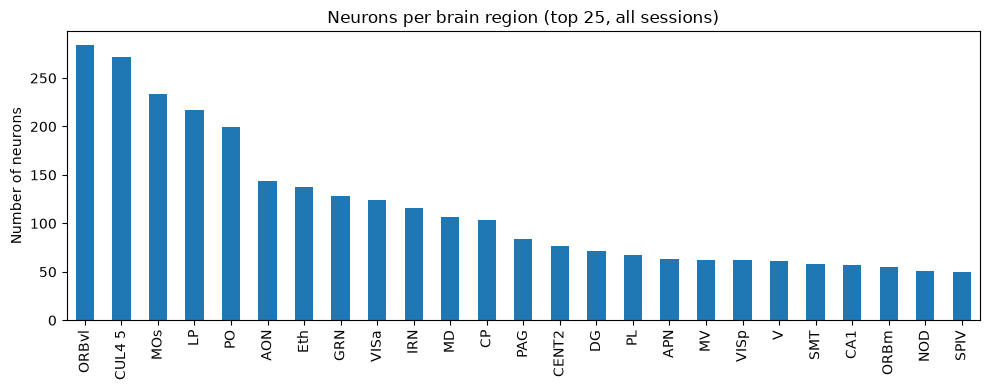

In [3]:
all_regions = pd.Series(
    np.concatenate([np.asarray(d["neuron_region"]).astype(str) for d in sessions.values()])
).value_counts()

print("Distinct regions in the whole dataset:", int(all_regions.size))
display(all_regions.rename("neurons").to_frame().head(25))

fig, ax = plt.subplots(figsize=(10, 4))
all_regions.head(25).plot.bar(ax=ax)
ax.set_ylabel("Number of neurons")
ax.set_title("Neurons per brain region (top 25, all sessions)")
plt.tight_layout()
plt.show()

## 3. Which regions each session has

In [4]:
matrix = pd.DataFrame(
    {sid: pd.Series(np.asarray(d["neuron_region"]).astype(str)).value_counts()
     for sid, d in sessions.items()}
).fillna(0).astype(int)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]

in_n_sessions = (matrix > 0).sum(axis=1)
print("Regions in only one session:", int((in_n_sessions == 1).sum()))
print("Regions in more than one session:", int((in_n_sessions > 1).sum()))
print("Regions with at least", min_per_region, "neurons in at least one session:",
      int((matrix >= min_per_region).any(axis=1).sum()))
display(matrix.head(25))

Regions in only one session: 40
Regions in more than one session: 25
Regions with at least 5 neurons in at least one session: 57


,746d1902-fa59-4cab-b0aa-013be36060d5,ee40aece-cffd-4edb-a4b6-155f158c666a,f10efe41-0dc0-44d0-8f26-5ff68dca23e9,56b57c38-2699-4091-90a8-aba35103155e,4d8c7767-981c-4347-8e5e-5d5fffe38534,6274dda8-3a59-4aa1-95f8-a8a549c46a26,2bdf206a-820f-402f-920a-9e86cd5388a4,8207abc6-6b23-4762-92b4-82e05bed5143,dfbe628d-365b-461c-a07f-8b9911ba83aa,09394481-8dd2-4d5c-9327-f2753ede92d7
ORBvl,0,0,0,0,61,0,0,84,139,0
CUL4 5,22,0,219,0,0,0,0,0,0,31
MOs,0,0,0,0,135,0,0,51,48,0
LP,72,24,0,69,0,0,52,0,0,0
PO,111,46,0,42,0,0,0,0,0,0
AON,0,0,0,0,18,0,0,72,54,0
Eth,0,51,0,32,0,0,55,0,0,0
GRN,34,0,22,72,0,0,0,0,0,0
VISa,0,44,0,29,0,0,51,0,0,0
IRN,45,0,29,0,0,0,0,0,0,42


## 4. What the excluded regions removed

In [5]:
import yaml
from iblatlas.atlas import BrainRegions
from brainwidemap import load_good_units

from src.common.settings import connect_ibl

with (ROOT / "sessions.yaml").open(encoding="utf-8") as f:
    selection = yaml.safe_load(f)
pids = {s["session_id"]: s["pids"] for s in selection["sessions"]}

one = connect_ibl()
br = BrainRegions()

rows = []
for sid in ready:
    total = 0
    removed = 0
    for pid in pids[sid]:
        _, clusters = load_good_units(one, pid, qc=config["data"]["good_neuron_qc"])
        acronyms = br.id2acronym(clusters["atlas_id"].to_numpy(),
                                 mapping=config["data"]["region_mapping"])
        total += int(len(acronyms))
        removed += int(np.isin(acronyms, excluded).sum())
    rows.append({
        "session_id": sid,
        "good_units": total,
        "removed_by_excluded_regions": removed,
        "kept": total - removed,
        "removed_percent": round(100 * removed / total, 1),
    })

exclusion = pd.DataFrame(rows)
display(exclusion)
print("Good units in all sessions:", int(exclusion["good_units"].sum()))
print("Removed by the excluded regions:", int(exclusion["removed_by_excluded_regions"].sum()))

D:\projects\brain-decoding\.venv\Lib\site-packages\one\webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


  0%|          | 0/3.0 [00:00<?, ?it/s]

 33%|███▎      | 1/3.0 [00:00<00:00,  2.05it/s]

 67%|██████▋   | 2/3.0 [00:00<00:00,  2.04it/s]

100%|██████████| 3/3.0 [00:01<00:00,  2.61it/s]

100%|██████████| 3/3.0 [00:01<00:00,  2.43it/s]

,session_id,good_units,removed_by_excluded_regions,kept,removed_percent
0,746d1902-fa59-4cab-b0aa-013be36060d5,456,27,429,5.9
1,ee40aece-cffd-4edb-a4b6-155f158c666a,466,39,427,8.4
2,f10efe41-0dc0-44d0-8f26-5ff68dca23e9,426,30,396,7.0
3,56b57c38-2699-4091-90a8-aba35103155e,424,33,391,7.8
4,4d8c7767-981c-4347-8e5e-5d5fffe38534,389,0,389,0.0
5,6274dda8-3a59-4aa1-95f8-a8a549c46a26,376,27,349,7.2
6,2bdf206a-820f-402f-920a-9e86cd5388a4,376,30,346,8.0
7,8207abc6-6b23-4762-92b4-82e05bed5143,380,48,332,12.6
8,dfbe628d-365b-461c-a07f-8b9911ba83aa,351,20,331,5.7
9,09394481-8dd2-4d5c-9327-f2753ede92d7,367,41,326,11.2


Good units in all sessions: 4011
Removed by the excluded regions: 295


In [6]:
kept = exclusion.set_index("session_id")["kept"]
stored = per_session.set_index("session_id")["n_neurons"].reindex(kept.index)
assert (kept == stored).all(), "Kept neurons do not match the saved sessions."
print("Check passed: kept neurons match the neurons saved in data/processed.")

Check passed: kept neurons match the neurons saved in data/processed.


## 5. Firing rates in the pre-movement window

Neurons in total: 3716
Median firing rate (Hz): 4.72
Mean firing rate (Hz): 11.05
Highest firing rate (Hz): 171.73
Neurons with no spike in the window: 59


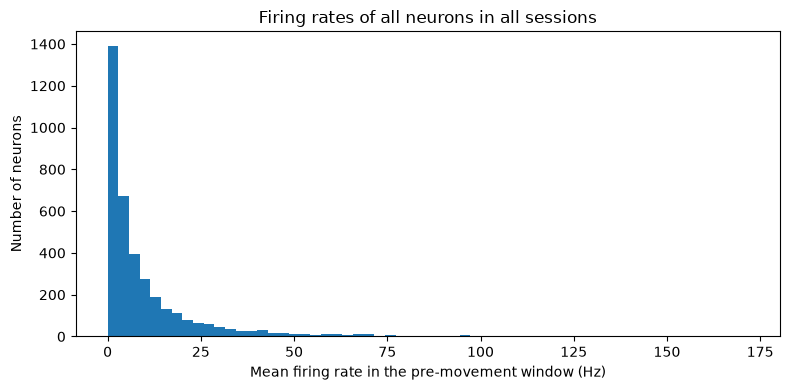

In [7]:
mean_rates = np.concatenate(
    [np.asarray(d["X"], dtype=float).mean(axis=0) for d in sessions.values()]
)

print("Neurons in total:", int(mean_rates.size))
print("Median firing rate (Hz):", round(float(np.median(mean_rates)), 2))
print("Mean firing rate (Hz):", round(float(mean_rates.mean()), 2))
print("Highest firing rate (Hz):", round(float(mean_rates.max()), 2))
print("Neurons with no spike in the window:", int((mean_rates == 0).sum()))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mean_rates, bins=60)
ax.set_xlabel("Mean firing rate in the pre-movement window (Hz)")
ax.set_ylabel("Number of neurons")
ax.set_title("Firing rates of all neurons in all sessions")
plt.tight_layout()
plt.show()

## Conclusions

- The 10 ready sessions hold 3716 neurons and 4872 trials in total.
- The neurons fall in 65 Beryl regions, but only 25 of them appear in more than one session. The other 40 appear in one session only, so any claim about a single region rests on one session.
- The largest region in a session ranges from 61 neurons to 219 neurons, so the sessions are not comparable neuron by neuron.
- The excluded regions root and void removed 295 good units out of 4011, about 7 percent. One session lost none and one lost 12.6 percent.
- The kept neurons match the neurons saved in data/processed exactly, so the exclusion step in neurons.py does what it says.
- In the 100 ms before movement the median neuron fires at 4.72 Hz and the mean is 11.05 Hz. 59 neurons do not fire at all in the window, so they carry no information for the models.